<a href="https://colab.research.google.com/github/nivethashrikm08-blip/MLA0202-FML/blob/main/ML%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANN using Backpropagation

Input		Actual	Predicted
[0 0] 	 0 	 0
[0 1] 	 1 	 1
[1 0] 	 1 	 1
[1 1] 	 0 	 0


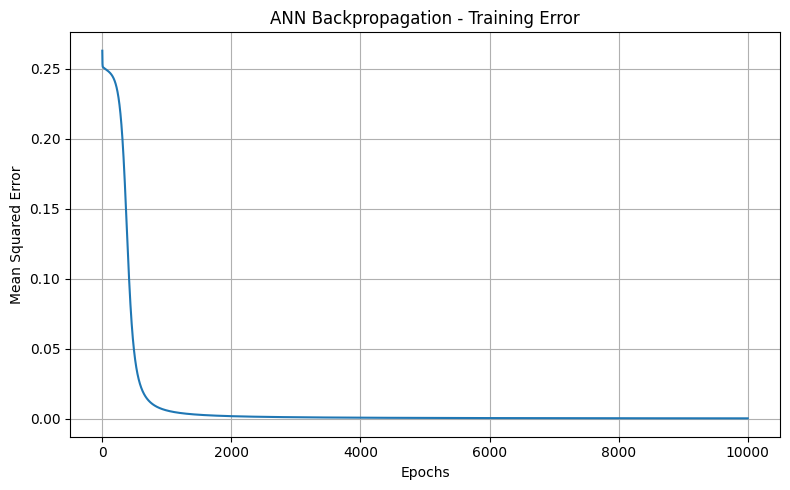

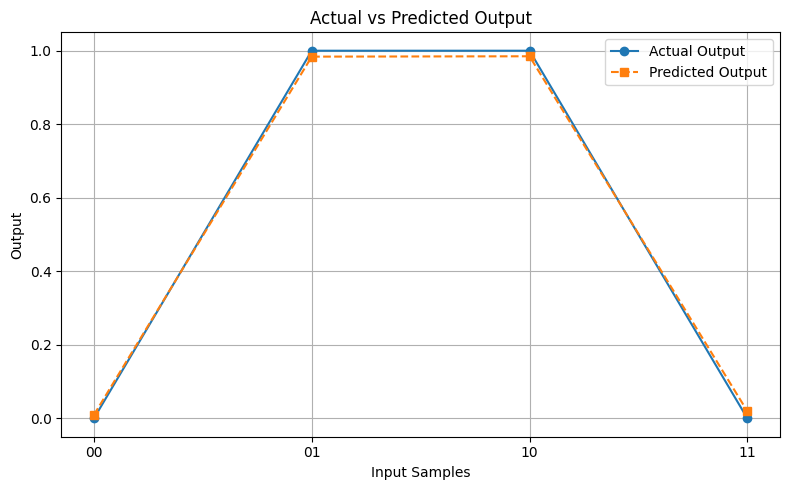

In [ ]:

# Artificial Neural Network using Backpropagation
# Dataset: XOR (input-output dataset)

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create the dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])

# Step 2: Define the sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Derivative of sigmoid
def sigmoid_derivative(x):
    return x * (1 - x)

# Step 3: Initialize weights and biases
np.random.seed(42)

input_neurons = 2
hidden_neurons = 4
output_neurons = 1

W1 = np.random.uniform(-1, 1, (input_neurons, hidden_neurons))
b1 = np.zeros((1, hidden_neurons))

W2 = np.random.uniform(-1, 1, (hidden_neurons, output_neurons))
b2 = np.zeros((1, output_neurons))

learning_rate = 0.5
epochs = 10000
loss_history = []

# Step 4: Train the neural network using backpropagation
for epoch in range(epochs):

    # Forward propagation
    hidden_input = np.dot(X, W1) + b1
    hidden_output = sigmoid(hidden_input)

    final_input = np.dot(hidden_output, W2) + b2
    predicted_output = sigmoid(final_input)

    # Calculate mean squared error
    error = y - predicted_output
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Backpropagation: output layer
    output_delta = error * sigmoid_derivative(predicted_output)

    # Backpropagation: hidden layer
    hidden_error = np.dot(output_delta, W2.T)
    hidden_delta = hidden_error * sigmoid_derivative(hidden_output)

    # Update weights and biases
    W2 += learning_rate * np.dot(hidden_output.T, output_delta)
    b2 += learning_rate * np.sum(output_delta, axis=0, keepdims=True)

    W1 += learning_rate * np.dot(X.T, hidden_delta)
    b1 += learning_rate * np.sum(hidden_delta, axis=0, keepdims=True)

# Step 5: Test the trained network
hidden_output = sigmoid(np.dot(X, W1) + b1)
predicted_output = sigmoid(np.dot(hidden_output, W2) + b2)

print("ANN using Backpropagation")
print("\nInput\t\tActual\tPredicted")
for i in range(len(X)):
    predicted_class = 1 if predicted_output[i][0] >= 0.5 else 0

    print(X[i], "\t", y[i][0], "\t", predicted_class)

# Step 6: Plot the training error graph
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("ANN Backpropagation - Training Error")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.tight_layout()
plt.show()

# Step 7: Plot the predicted output graph
plt.figure(figsize=(8, 5))
plt.plot(range(4), y.flatten(), 'o-', label="Actual Output")
plt.plot(range(4), predicted_output.flatten(), 's--',
         label="Predicted Output")
plt.xticks(range(4), ['00', '01', '10', '11'])
plt.xlabel("Input Samples")
plt.ylabel("Output")
plt.title("Actual vs Predicted Output")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
